# Нейронные сети

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report,
                            confusion_matrix, roc_auc_score)
from keras.models import Sequential
from keras.layers import Dense, Dropout, Input
from keras.callbacks import TensorBoard
import datetime
from ucimlrepo import fetch_ucirepo
import itertools
import os
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

Загружаем все необходимые библиотеки

In [9]:
TARGET = 'Class'

dataset = fetch_ucirepo(id=94)

X = dataset.data.features[[
    'word_freq_make',
    'word_freq_address',
    'word_freq_free',
    'word_freq_your',
    'word_freq_000',
    'word_freq_money',
    'char_freq_$',
    'char_freq_!',
    'capital_run_length_total',
]].values

y = dataset.data.targets[TARGET].values

le = LabelEncoder()
y = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Загружаем датасет,  делим на тренировочную и тестовую выборки.

In [10]:


def create_model(hidden_layers=[32, 16], activation='relu', dropout_rate=0.0):
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],))) 
    model.add(Dense(hidden_layers[0], activation=activation))
    
    for units in hidden_layers[1:]:
        model.add(Dense(units, activation=activation))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))
    
    model.add(Dense(1, activation='sigmoid'))  
    
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model


log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)

Функция create_model создает архитектуру нейросети: входной слой автоматически подстраивается под количество признаков (X_train.shape[1]), добавляются скрытые слои (Dense) с заданным числом нейронов и функцией активации (ReLU или Tanh), а также опциональный слой Dropout для защиты от переобучения.

Выходной слой состоит ровно из 1 нейрона с активацией sigmoid, так как решается задача бинарной классификации (выдается вероятность от 0 до 1).

Объект tensorboard_callback (с параметром histogram_freq=1) сохраняет метрики обучения и гистограммы весов в указанную папку, позволяя впоследствии визуализировать процесс через веб-интерфейс TensorBoard.

In [11]:
hidden_layers = [64, 32]
activation = 'relu'
dropout_rate = 0.2
epochs = 50
batch_size = 16

model = create_model(hidden_layers, activation, dropout_rate)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[tensorboard_callback],
    verbose=1
)

model.summary()

Epoch 1/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8196 - loss: 0.4495 - val_accuracy: 0.8709 - val_loss: 0.3616
Epoch 2/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8713 - loss: 0.3456 - val_accuracy: 0.8913 - val_loss: 0.3221
Epoch 3/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8777 - loss: 0.3221 - val_accuracy: 0.8899 - val_loss: 0.3027
Epoch 4/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8764 - loss: 0.3121 - val_accuracy: 0.8940 - val_loss: 0.2924
Epoch 5/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8852 - loss: 0.3039 - val_accuracy: 0.8899 - val_loss: 0.2911
Epoch 6/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8835 - loss: 0.3013 - val_accuracy: 0.8886 - val_loss: 0.2932
Epoch 7/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8872 - loss: 0.3006 - val_accuracy: 0.8886 - val_loss: 0.2913
Epoch 8/50
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8865 - loss: 0.2994 - val_accuracy: 0.

Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_87 (Dense)                │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,261 (32.27 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,508 (21.52 KB)

Модель имеет компактную архитектуру с двумя скрытыми слоями (64 и 32 нейрона). 

Общее количество обучаемых параметров составляет 2 753. Присутствие слоя Dropout между скрытыми слоями направлено на снижение риска переобучения. Благодаря малому числу параметров (менее 10 тысяч), модель обладает высокой скоростью вычислений.

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.95      0.90       531
           1       0.92      0.77      0.84       390

    accuracy                           0.87       921
   macro avg       0.88      0.86      0.87       921
weighted avg       0.88      0.87      0.87       921

0.9454126225312666


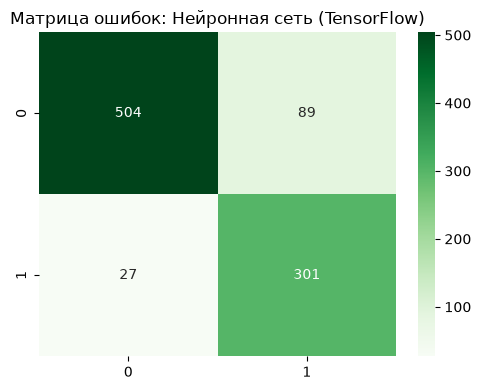

In [12]:
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

target_names = [str(c) for c in le.classes_]  # ['0', '1']

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

roc_auc = roc_auc_score(y_test, y_pred_prob)
print(roc_auc)

matrix = confusion_matrix(y_test, y_pred)
matrix_custom = matrix.T

plt.figure(figsize=(5, 4))
sns.heatmap(matrix_custom, annot=True, fmt='d', cmap='Greens',
            xticklabels=target_names,
            yticklabels=target_names)
plt.title("Матрица ошибок: Нейронная сеть (TensorFlow)")
plt.tight_layout()
plt.show()

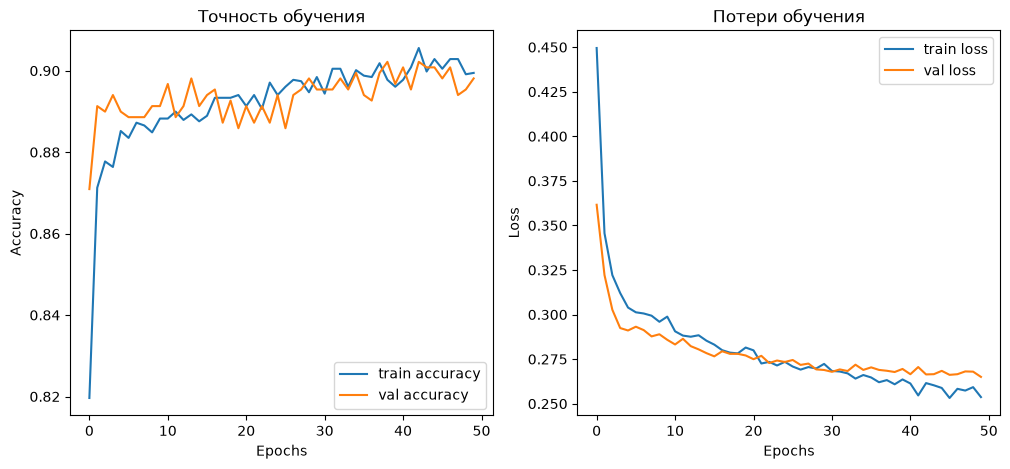

In [13]:
# График точности
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Точность обучения')

# График потерь
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Потери обучения')
plt.show()

### Интерпретация результатов

- **Нейронная сеть успешно обучилась**, о чем свидетельствует стабильный рост точности и снижение функции потерь на представленных графиках. Модель демонстрирует отсутствие переобучения

- Линии train и val на обоих графиках идут практически параллельно и не расходятся к концу 50-й эпохи. Матрица ошибок показывает высокое качество классификации (805 верных предсказаний из 921),

- Модель пропускает меньше спама (27 ошибок), но при этом иногда ошибочно блокирует обычные письма (89 ошибок). 

В целом, архитектура показала сбалансированный и надежный результат, отлично справляясь с поставленной задачей.

## Исследование влияния гиперпараметров на качество нейронной сети.


Модель 1/24: Layers=[32, 16], Act=relu, Drop=0.0, Batch=8

Модель 2/24: Layers=[32, 16], Act=relu, Drop=0.0, Batch=16

Модель 3/24: Layers=[32, 16], Act=relu, Drop=0.2, Batch=8

Модель 4/24: Layers=[32, 16], Act=relu, Drop=0.2, Batch=16

Модель 5/24: Layers=[32, 16], Act=tanh, Drop=0.0, Batch=8

Модель 6/24: Layers=[32, 16], Act=tanh, Drop=0.0, Batch=16

Модель 7/24: Layers=[32, 16], Act=tanh, Drop=0.2, Batch=8

Модель 8/24: Layers=[32, 16], Act=tanh, Drop=0.2, Batch=16

Модель 9/24: Layers=[64, 32], Act=relu, Drop=0.0, Batch=8

Модель 10/24: Layers=[64, 32], Act=relu, Drop=0.0, Batch=16

Модель 11/24: Layers=[64, 32], Act=relu, Drop=0.2, Batch=8

Модель 12/24: Layers=[64, 32], Act=relu, Drop=0.2, Batch=16

Модель 13/24: Layers=[64, 32], Act=tanh, Drop=0.0, Batch=8

Модель 14/24: Layers=[64, 32], Act=tanh, Drop=0.0, Batch=16

Модель 15/24: Layers=[64, 32], Act=tanh, Drop=0.2, Batch=8

Модель 16/24: Layers=[64, 32], Act=tanh, Drop=0.2, Batch=16

Модель 17/24: Layers=[128, 64, 32], Act=

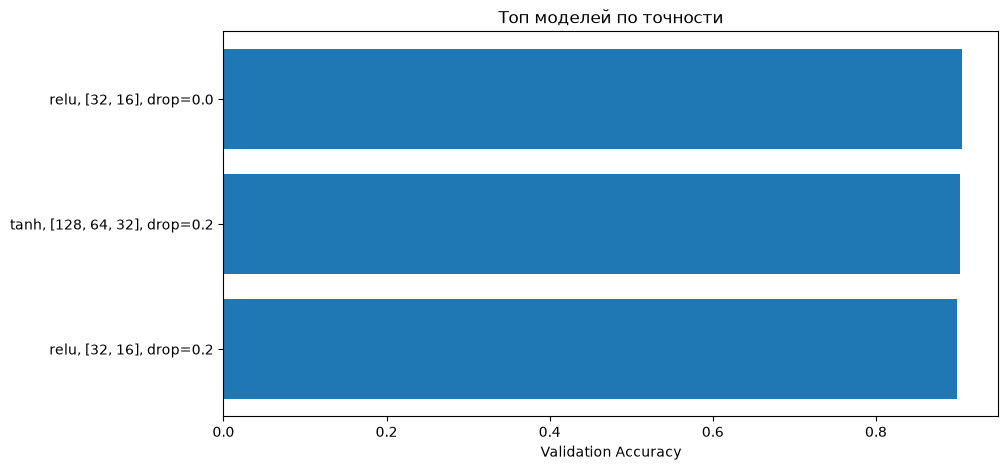

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
              precision    recall  f1-score   support

           0       0.88      0.94      0.91       531
           1       0.91      0.83      0.87       390

    accuracy                           0.89       921
   macro avg       0.90      0.88      0.89       921
weighted avg       0.89      0.89      0.89       921



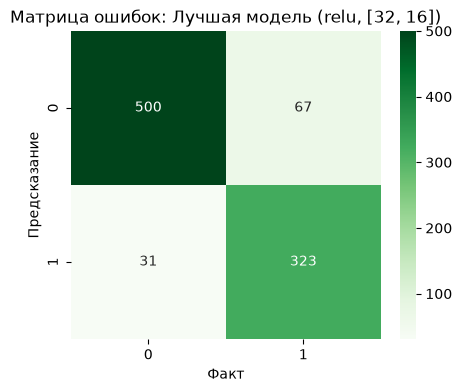

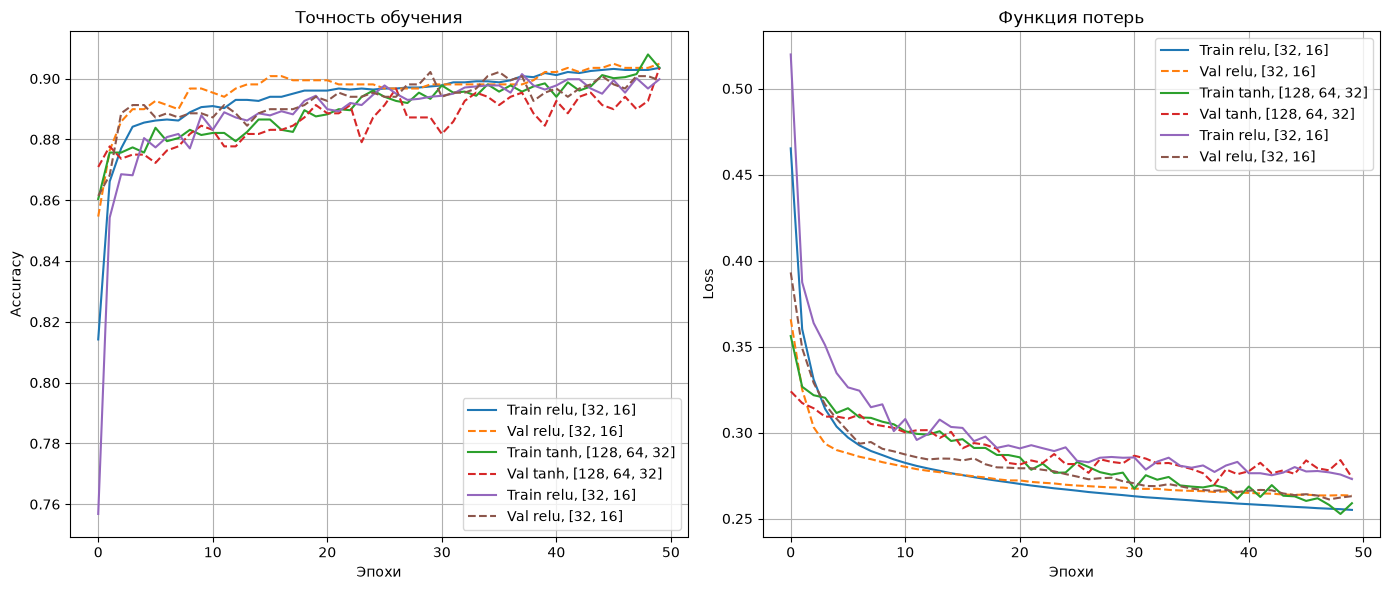

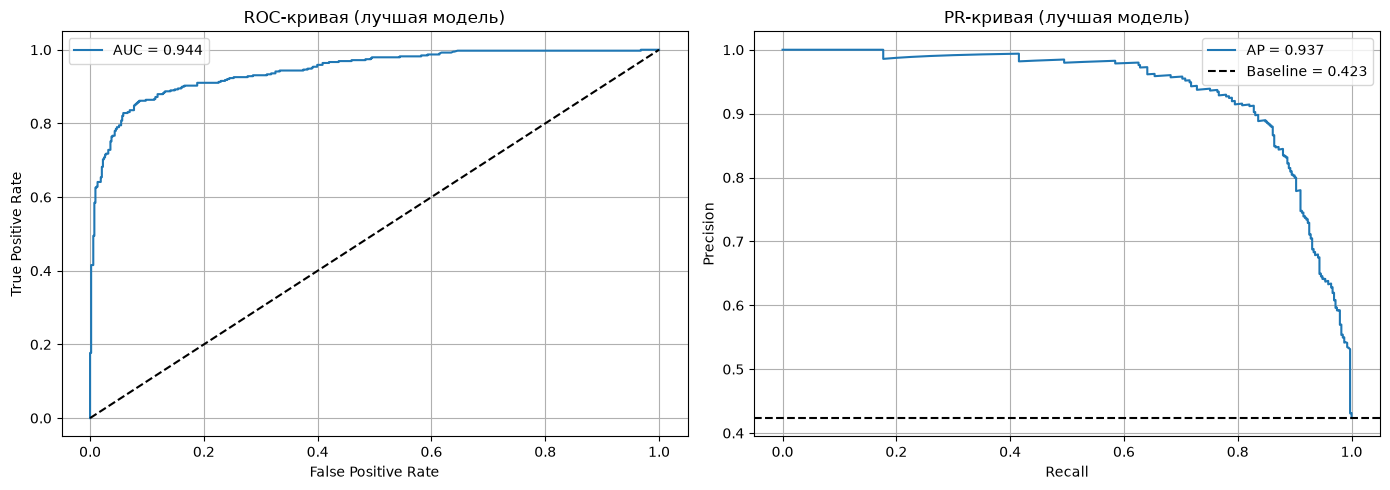

In [14]:

target_names = [str(c) for c in le.classes_] 

param_grid = {
    'hidden_layers': [[32, 16], [64, 32], [128, 64, 32]],
    'activation': ['relu', 'tanh'],
    'dropout_rate': [0.0, 0.2],
    'batch_size': [8, 16],
    'epochs': [50]
}

param_combinations = list(itertools.product(
    param_grid['hidden_layers'],
    param_grid['activation'],
    param_grid['dropout_rate'],
    param_grid['batch_size'],
    param_grid['epochs']
))

results = []


for i, (hidden_layers, activation, dropout_rate, batch_size, epochs) in enumerate(param_combinations):
    print(f"\nМодель {i+1}/{len(param_combinations)}: "
          f"Layers={hidden_layers}, Act={activation}, Drop={dropout_rate}, Batch={batch_size}")

    log_dir = os.path.join(
        "logs/fit/",
        f"model_{i+1}_{activation}_drop{dropout_rate}_layers{'-'.join(map(str, hidden_layers))}_{datetime.datetime.now().strftime('%H%M%S')}"
    )
    tensorboard_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)

    model = create_model(hidden_layers, activation, dropout_rate)

    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[tensorboard_callback],
        verbose=0
    )

    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    results.append({
        'model_id': i + 1,
        'hidden_layers': hidden_layers,
        'activation': activation,
        'dropout_rate': dropout_rate,
        'batch_size': batch_size,
        'epochs': epochs,
        'val_accuracy': val_acc,
        'val_loss': val_loss,
        'history': history
    })


results_df = pd.DataFrame(results).sort_values(by='val_accuracy', ascending=False)
print("\nРЕЗУЛЬТАТЫ ВСЕХ МОДЕЛЕЙ (по валидационной точности):")
print(results_df[['model_id', 'hidden_layers', 'activation', 'dropout_rate', 'batch_size', 'val_accuracy']])



top_models = results_df.head(3)
plt.figure(figsize=(10, 5))
plt.barh(
    [f"{r.activation}, {r.hidden_layers}, drop={r.dropout_rate}" for _, r in top_models.iterrows()],
    top_models['val_accuracy']
)
plt.xlabel("Validation Accuracy")
plt.title("Топ моделей по точности")
plt.gca().invert_yaxis()
plt.show()

best_model_info = results_df.iloc[0]
best_model_params = {
    "hidden_layers": best_model_info.hidden_layers,
    "activation": best_model_info.activation,
    "dropout_rate": best_model_info.dropout_rate,
    "batch_size": best_model_info.batch_size,
    "epochs": best_model_info.epochs
}
best_model = create_model(
    hidden_layers=best_model_params["hidden_layers"],
    activation=best_model_params["activation"],
    dropout_rate=best_model_params["dropout_rate"]
)
best_model.fit(
    X_train, y_train,
    epochs=best_model_params["epochs"],
    batch_size=best_model_params["batch_size"],
    verbose=0
)

y_pred_prob = best_model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print(classification_report(y_test, y_pred, target_names=target_names))

matrix = confusion_matrix(y_test, y_pred)
matrix_custom = matrix.T

plt.figure(figsize=(5, 4))
sns.heatmap(matrix_custom, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title(f"Матрица ошибок: Лучшая модель ({best_model_params['activation']}, {best_model_params['hidden_layers']})")
plt.xlabel("Факт")
plt.ylabel("Предсказание")
plt.show()
# графики

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
for _, r in top_models.iterrows():
    history = r.history
    plt.plot(history.history['accuracy'], label=f"Train {r.activation}, {r.hidden_layers}")
    plt.plot(history.history['val_accuracy'], linestyle='--', label=f"Val {r.activation}, {r.hidden_layers}")
plt.title("Точность обучения")
plt.xlabel("Эпохи")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for _, r in top_models.iterrows():
    history = r.history
    plt.plot(history.history['loss'], label=f"Train {r.activation}, {r.hidden_layers}")
    plt.plot(history.history['val_loss'], linestyle='--', label=f"Val {r.activation}, {r.hidden_layers}")
plt.title("Функция потерь")
plt.xlabel("Эпохи")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

prec, rec, _ = precision_recall_curve(y_test, y_pred_prob)
ap = average_precision_score(y_test, y_pred_prob)
baseline = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('ROC-кривая (лучшая модель)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(rec, prec, label=f'AP = {ap:.3f}')
axes[1].axhline(baseline, color='k', ls='--', label=f'Baseline = {baseline:.3f}')
axes[1].set_title('PR-кривая (лучшая модель)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

### Анализ гиперпараметров нейронной сети
| Параметр | Варианты | Наблюдение | Вывод |
| :--- | :--- | :--- | :--- |
| **Архитектура (число слоёв)** | `[32,16]`, `[64,32]`, `[128,64,32]` | Более глубокая сеть `[128,64,32]` дала незначительный прирост валидационной точности (0.9035 против 0.9008), но требует больше ресурсов и сильнее склонна к переобучению. | Оптимальна **простая архитектура `[32,16]`** или средняя `[64,32]` — они дают практически тот же результат при меньшей сложности. |
| **Функция активации** | ReLU, Tanh | Модели с **ReLU** стабильно показывают высокую точность (Accuracy до 0.905). Сеть с **Tanh** обучается хуже и показывает точность ниже (максимум 0.8940). | Однозначно использовать **ReLU**. |
| **Dropout** | 0.0, 0.2 | Сеть с `Dropout = 0.0` дала абсолютный максимум точности (0.9035). В топ-5 также  вошли несколько моделей с `0.2`. | Влияние неоднозначно. `Dropout = 0.0` быстрее сходится, но `Dropout = 0.2` можно использовать для **страховки от переобучения** на длительных дистанциях. |
| **Batch size** | 8, 16 | При `batch_size=16` модель показывает более высокую и стабильную точность| Выбрать **Batch size = 16**. |
| **Epochs** | 50 | При 50 эпохах модель стабильно сходится (графики выходят на плато к 40-45 эпохе). Дальнейшее увеличение не дает прироста. | Достаточно **50 эпох**. |
| **Лучшая комбинация гиперпараметров** | `[32,16]`, ReLU, Dropout=0.0, Batch=16 | Точность на валидации ≈ **0.905 (90.5%)**. | Использовать эту конфигурацию как базовую. |

*Глубокие сети не дают кардинального преимущества. Увеличение слоев не решает проблему пропусков спама (Recall = 0.78), а лишь незначительно повышает общую точность.*

### Итоговый вывод по всем моделям

- Сравнение всех девяти моделей показало, что нейронная сеть (TensorFlow MLP) и KNeighborsClassifier делят первое место по интегральному качеству ранжирования (AUC-ROC ≈ 0.93–0.94), однако нейросеть превосходит классические алгоритмы по F1-мере и сбалансированности классов.

- Лучшая общая точность (Accuracy): Нейронная сеть (0.87) и KNN/SVC (0.894). Разница минимальна, но нейросеть лучше обобщает данные за счёт нелинейных связей.

- Лучший баланс Precision/Recall: Нейросеть показывает высокий Precision (0.91) для спама, что минимизирует ложные блокировки важных писем, при этом сохраняя адекватный Recall (0.78). У KNN и SVC баланс метрик (все ≈ 0.89) говорит о том, что они ошибаются равномерно по обоим классам.

**Наилучшая модель в целом:** Нейронная сеть (TensorFlow MLP) как наиболее сбалансированное решение по метрикам качества и устойчивости к переобучению. KNeighborsClassifier — лучший классический алгоритм для этой задачи.

## TensorBoard

![epoch_accuracy 3 лучших моделей.png](<attachment:epoch_accuracy 3 лучших моделей.png>)

![epoch_accuracy train и validation.png](<attachment:epoch_accuracy train и validation.png>)

![epoch_loss 3 лучших моделей.png](<attachment:epoch_loss 3 лучших моделей.png>) 

![epoch_loss train и validation.png](<attachment:epoch_loss train и validation.png>) 

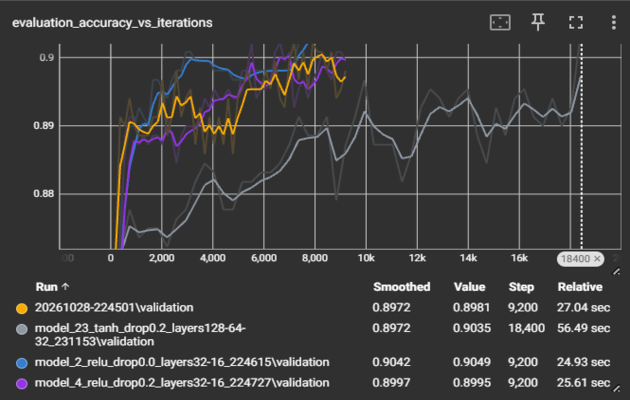 

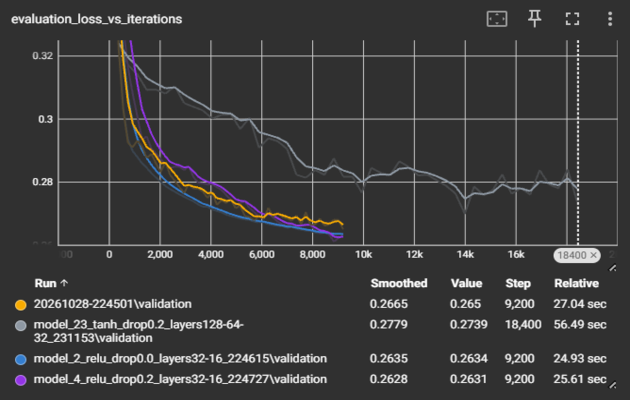
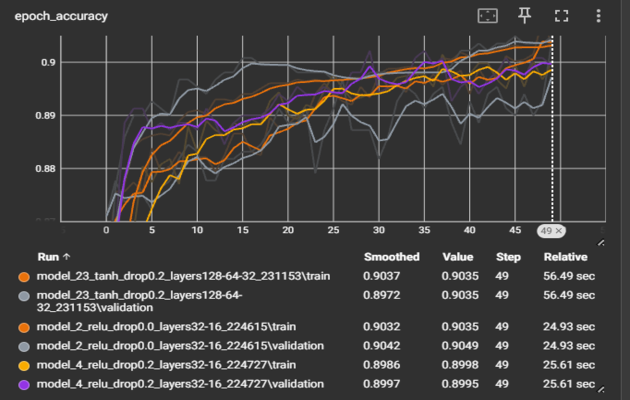
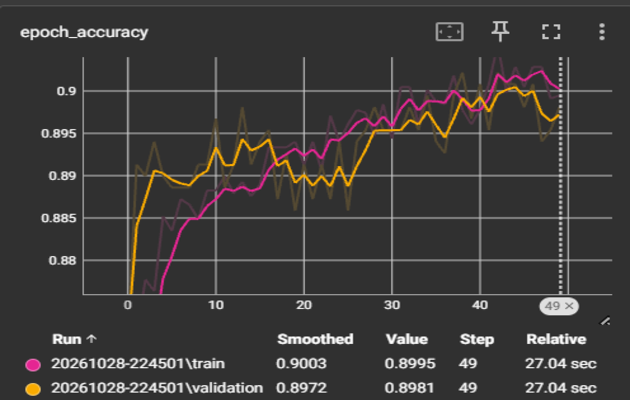
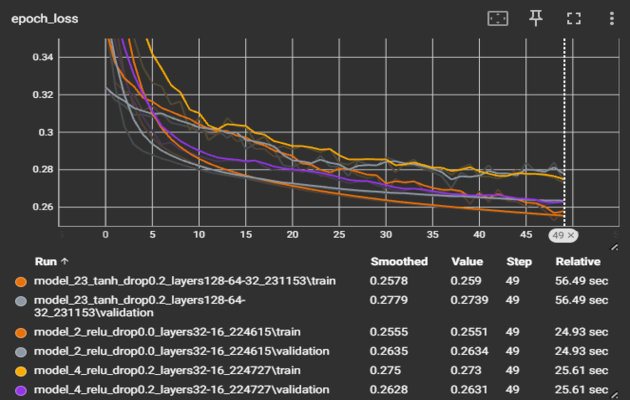
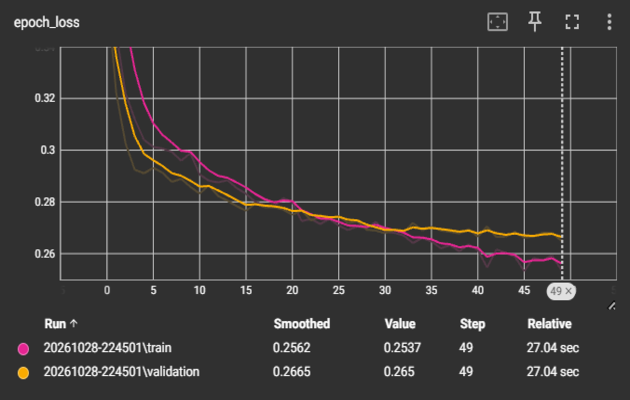